![Original climate-globe illustration introducing Days, seasons, and record claims; illustrative, not a data map](assets/atlas-splash.png)

# 25 · Days, seasons, and record claims

**Guiding question:** When is a record comparison fair?

**Data:** Real C3S/ECMWF ERA5 Climate Pulse CSV snapshots retrieved 2026-11-20; CC BY 4.0  
**Time:** 20–35 minutes · **Prerequisites:** basic Python; run cells from top to bottom.  
**Author:** JupyterLite-C3S-Atlas contributors (AI assisted) · **Created/updated:** 2026-11-20  
**Inputs:** bundled reference files and/or seeded examples specified below. **Outputs:** tables, figures, and any explicitly named local exports; source data are not modified.  
**Runtime:** Python/Pyodide; NumPy, pandas, Matplotlib, Plotly; versions and tests are recorded in the validation report.  
**Change log:** initial educational chapter. **Contact:** [repository issues](https://github.com/jltobias/JupyterLite-C3S-Atlas/issues).

[Open in JupyterLite Lab](https://jltobias.github.io/JupyterLite-C3S-Atlas/lite/lab/index.html?path=25-time-ranks-and-records.ipynb) · [Official Atlas](https://atlas.climate.copernicus.eu/)


## Read the evidence

A rank depends on the comparison set. Compare October with other Octobers,
        keep the variable and region fixed, name the archive period, and state how ties
        are handled. A rank is descriptive, not a return period or a probability estimate.

        Three-month means suppress short fluctuations but adjacent windows share two
        months; they are not independent samples. A centred mean has no value at either
        end without a complete window. A recent daily export also contains a partial month:
        averaging that fragment and labelling it a full November mean would be misleading.
        Here we aggregate daily **12 UTC SST** values and keep that statistic distinct
        from the source's monthly product.

## Start the browser lab

Run this setup cell once. First load needs internet for the Python runtime and packages. The remaining lesson uses bundled data. If a 3D view is unavailable, use the 2D/table alternative. Download your edited notebook before clearing browser storage.

In [1]:
# Install only in the browser kernel; desktop dependencies come from requirements.txt.
import sys
if sys.platform == "emscripten":
    import piplite
    await piplite.install(["numpy", "pandas", "matplotlib", "plotly==6.5.0"])

import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.graph_objects as go
from IPython.display import display
from atlas_helpers import (
    DATA, SYNTHETIC, COLORS, show, monthly_demo, anomalies, regular_grid,
    area_mean, coastlines, map_figure, globe_figure, warming_levels, load_monthly_csv,
)
print("Ready. Browser edits live in this browser; download work you want to keep.")


Ready. Browser edits live in this browser; download work you want to keep.


## Require a complete month

In [2]:
from pulse_helpers import (
    load_pulse, complete_months, rank_same_month, region_rings, region_geojson,
    region_map, region_globe, REGIONS, ANOM, REL, CREDIT, BASE,
)
daily = load_pulse(aggregation="daily")
monthly_from_daily = complete_months(daily)
official = load_pulse()
audit = monthly_from_daily.merge(official[["date", ANOM]], on="date", how="inner")
audit["difference"] = audit["mean"] - audit[ANOM]
display(audit.tail(5))
print("Daily file ends:", daily.date.max().date())
print("Last complete derived month:", monthly_from_daily.date.max().date())
print("These products have different stated time support; agreement is not assumed.")

,date,mean,count,expected,anom_1991_2020,difference
569,2026-06-01,1.470660,30,30,1.4730,-0.002340
570,2026-07-01,2.058345,31,31,2.0584,-0.000055
571,2026-08-01,2.683384,31,31,2.6855,-0.002116
572,2026-09-01,3.022893,30,30,3.0219,0.000993
573,2026-10-01,3.232168,31,31,3.2345,-0.002332


Daily file ends: 2026-11-18
Last complete derived month: 2026-10-01
These products have different stated time support; agreement is not assumed.


## A rank with its denominator and a rolling window

,2026-10 · traditional Niño 3.4
value,3.2345
rank,1
n,48
ties,1
rule,1 + number strictly warmer; same calendar month


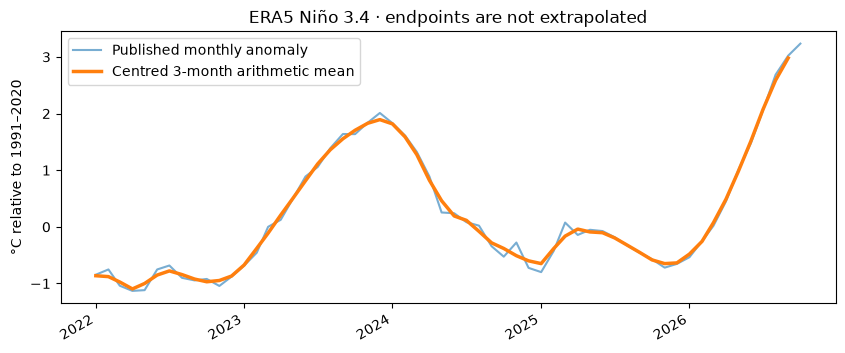

In [3]:
df = load_pulse()
date = df.date.max()
display(pd.Series(rank_same_month(df, date)).to_frame(f"{date:%Y-%m} · traditional Niño 3.4"))
df["centred_three_month"] = df[ANOM].rolling(3, center=True, min_periods=3).mean()
part = df[df.year >= 2022]
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(part.date, part[ANOM], label="Published monthly anomaly", alpha=.6)
ax.plot(part.date, part.centred_three_month, lw=2.5, label="Centred 3-month arithmetic mean")
ax.set(ylabel="°C relative to 1991–2020", title="ERA5 Niño 3.4 · endpoints are not extrapolated")
ax.legend(); fig.autofmt_xdate(); plt.show()

## Try it and explain

Rank another month. Replace the centred mean with a trailing mean and explain the changed date label.

**Interpretation check:** For a centred January value the window is December–February. A trailing January value uses November–January. Neither is automatically an agency-specific ONI or RONI product.

## Transfer to the official tools

Select monthly and annual views in Pulse. Inspect the information panel for each aggregation and compare its record definition with the denominator used here.

Record the selections, source version, units, periods, and uncertainty legend. These independent lessons do not duplicate every production workflow in the official tools.

## Sources and credit

- [C3S Atlas dataset and DOI](https://doi.org/10.24381/cds.h35hb680)
- [CSIC / Predictia Atlas user guide](https://confluence.ecmwf.int/spaces/CKB/pages/394237545/Copernicus+Interactive+Climate+Atlas+User+Guide)
- [Official C3S Atlas User Tools and contributors](https://ecmwf-projects.github.io/c3s-atlas/)
- [C3S Climate Pulse 2.0 announcement (10 November 2026)](https://climate.copernicus.eu/new-version-climate-pulse-provides-new-monitoring-el-nino-conditions)
- [Climate Pulse FAQs and methodology](https://pulse.climate.copernicus.eu/faqs)
- [Climate Pulse credits and citations](https://pulse.climate.copernicus.eu/credits)
- [ERA5 monthly data: C3S/ECMWF and ERA5 contributors](https://doi.org/10.24381/cds.f17050d7)
- [Hersbach et al. (2020): The ERA5 global reanalysis](https://doi.org/10.1002/qj.3803)
- [ERA5 hourly data underpinning daily exports](https://doi.org/10.24381/cds.adbb2d47)

Original teaching text and code; original AI-generated splash illustration. Real reference files retain their source licences. Synthetic examples are not Copernicus measurements. See [credits](credits.md) and [data guide](data-guide.md).

**Continue:** [One statistic, two geographic views](26-pulse-maps-and-globes.ipynb)